# Práctica: **Regresión** con Red Neuronal (MLP) en PyTorch

Seguimos la *receta de entrenamiento* del cuadernillo `07 receta_entrenamiento`:

> EDA → normalizar → split train/val/test → Dataset/DataLoader → modelo → validar (dims, fit 1 muestra, fit batch) → entrenar → evaluar.

**Objetivo de la práctica:** poder *reescribir de memoria* los bloques marcados con ⭐ (modelo y bucle de entrenamiento) sin mirar las soluciones.


## 1. Exploración de datos

Dataset UCI *Appliances energy prediction*: es el mismo que usaste en LAB3. Cada fila es una lectura de sensores en una casa.
**¿Cuál es el objetivo (y)?** La columna `Appliances` (consumo energético en Wh). Es **numérica y continua** → problema de **regresión**.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
df = pd.read_csv('../LAB3/energydata_complete.csv')
print('Shape:', df.shape)
df.head()

Shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


La columna **`Appliances`** es nuestro target `y`. El resto son las features `X`. Se descarta `date` porque es un timestamp, no aporta como número.

In [3]:
y = df.pop('Appliances').values.astype(np.float32)          # y: objetivo de regresión
X = df.drop(columns=['date']).values.astype(np.float32)   # X: features
print('X:', X.shape, '| y:', y.shape, '| rango de y:', round(y.min(),1), '-', round(y.max(),1))

X: (19735, 27) | y: (19735,) | rango de y: 10.0 - 1080.0


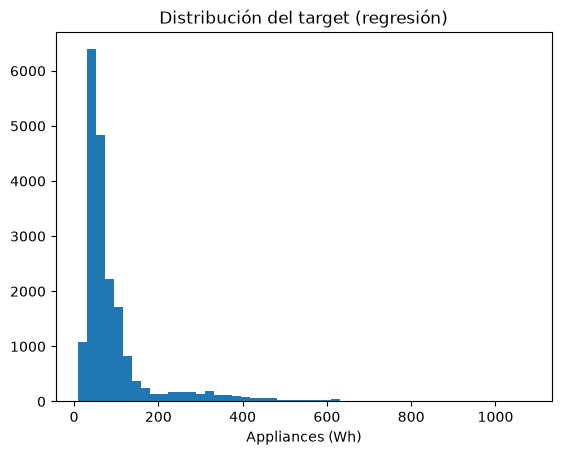

In [4]:
plt.hist(y, bins=50)
plt.xlabel('Appliances (Wh)')
plt.title('Distribución del target (regresión)')
plt.show()

## 2. División y normalización

- Dividimos **train / val / test** (el val para controlar overfitting, el test solo se toca al final).
- Normalizamos con **z-score** usando estadísticos **solo del train** (si usás los de todo el dataset, 'filtramos' información del test al entrenamiento).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)
print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

Train: 13814 | Val: 1974 | Test: 3947


In [6]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
sigma[sigma == 0] = 1
X_train = (X_train - mu) / sigma
X_val   = (X_val   - mu) / sigma
X_test  = (X_test  - mu) / sigma
print('media de X_train (~0):', round(X_train.mean(), 4))

media de X_train (~0): 0.0


## 3. Dataset y DataLoader

In [7]:
class Dataset(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X).float().to(device)
        self.Y = torch.from_numpy(Y).float().to(device)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, ix):
        return self.X[ix], self.Y[ix]

In [8]:
dataset = {
    'train': Dataset(X_train, y_train),
    'val': Dataset(X_val, y_val),
}
dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=128, shuffle=True),
    'val': torch.utils.data.DataLoader(dataset['val'], batch_size=512, shuffle=False),
}
print('Ejemplos train:', len(dataset['train']), '| Val:', len(dataset['val']))

Ejemplos train: 13814 | Val: 1974


## 4. Modelo ⭐ (escribilo de memoria)

- `D_in` = número de features.
- `D_out` = 1 **sin función de activación al final** (regresión → salida lineal, la combinamos con **MSE**).
- Capas ocultas con **ReLU** (la no-linealidad es lo que hace al MLP más poderoso que un perceptrón).

In [9]:
D_in = X.shape[1]   # 28 features
H = 64
D_out = 1            # regresión: 1 salida, sin activación final

def build_model(D_in=D_in, H=H, D_out=D_out):
    return torch.nn.Sequential(
        torch.nn.Linear(D_in, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, D_out)
    ).to(device)

## 5. Validación de la red (receta)

Antes de entrenar en todo, verificar: **(a)** dimensiones correctas, **(b)** que el modelo es capaz de aprenderse 1 muestra de memoria, **(c)** que aprende 1 batch. Si no aprende una muestra, hay un bug (pérdida equivocada, dimensiones, etc).

In [10]:
model = build_model()
test_input = torch.randn((64, D_in)).to(device)
out = model(test_input)
print('Entrada:', test_input.shape, '-> Salida:', out.shape)
assert out.shape == (64, D_out), "dimensiones incorrectas"
print("OK dimensiones")

Entrada: torch.Size([64, 27]) -> Salida: torch.Size([64, 1])
OK dimensiones


In [11]:
criterion = torch.nn.MSELoss()
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

ds1 = Dataset(X_train[:8], y_train[:8])
dl1 = torch.utils.data.DataLoader(ds1, batch_size=8)
for e in range(1, 101):
    for x_b, y_b in dl1:
        loss = criterion(model(x_b).squeeze(1), y_b)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    if not e % 20:
        print(f"Epoch {e} loss {loss.item():.5f}")

Epoch 20 loss 369.68112
Epoch 40 loss 51.67308
Epoch 60 loss 5.98950
Epoch 80 loss 0.47174
Epoch 100 loss 0.04736


In [12]:
ds64 = Dataset(X_train[:64], y_train[:64])
dl64 = torch.utils.data.DataLoader(ds64, batch_size=64, shuffle=True)
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
for e in range(1, 201):
    for x_b, y_b in dl64:
        loss = criterion(model(x_b).squeeze(1), y_b)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    if not e % 50:
        print(f"Epoch {e} loss {loss.item():.5f}")

Epoch 50 loss 5822.22656
Epoch 100 loss 3409.60791


Epoch 150 loss 1115.97876
Epoch 200 loss 83.32974


## 6. Función de entrenamiento ⭐ (escribila de memoria)

Bucle estándar por epoch:
1. `model.train()` → para cada batch: **forward**, **loss**, `zero_grad`, `backward`, `step`.
2. `model.eval()` + `with torch.no_grad()` → métricas en validación (sin calcular gradientes).
3. Guardar el **mejor modelo** (según val) y parar con **early stopping** si val deja de mejorar.

In [13]:
import numpy as np

def fit(model, dataloader, optimizer, epochs=50, log_each=10, early_stopping=5):
    criterion = torch.nn.MSELoss()
    hist_loss, hist_val = [], []
    best_val, steps = float('inf'), 0
    for e in range(1, epochs + 1):
        # --- entrenamiento
        model.train()
        _l = []
        for x_b, y_b in dataloader['train']:
            y_pred = model(x_b).squeeze(1)
            loss = criterion(y_pred, y_b)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            _l.append(loss.item())
        hist_loss.append(np.mean(_l))
        # --- validación
        model.eval()
        _vl = []
        with torch.no_grad():
            for x_b, y_b in dataloader['val']:
                y_pred = model(x_b).squeeze(1)
                _vl.append(criterion(y_pred, y_b).item())
        hist_val.append(np.mean(_vl))
        # --- guardar mejor modelo + early stopping
        if hist_val[-1] < best_val:
            best_val = hist_val[-1]
            steps = 0
            torch.save(model.state_dict(), 'ckpt_reg.pt')
        else:
            steps += 1
        if early_stopping and steps > early_stopping:
            print(f"Early stop en epoch {e}")
            break
        if not e % log_each:
            print(f"Epoch {e}/{epochs} loss {hist_loss[-1]:.4f} val_loss {hist_val[-1]:.4f}")
    model.load_state_dict(torch.load('ckpt_reg.pt', weights_only=True))
    return {'loss': hist_loss, 'val_loss': hist_val}

## 7. Entrenamiento

Configuración recomendada por el post: **Adam lr=0.001** como punto de partida.

In [14]:
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, dataloader, optimizer, epochs=50, log_each=10)

Epoch 10/50 loss 8988.5890 val_loss 8291.3309


Epoch 20/50 loss 8600.2298 val_loss 8019.4690


Epoch 30/50 loss 8189.5806 val_loss 7874.7025


Epoch 40/50 loss 7918.4213 val_loss 7713.2622


Epoch 50/50 loss 7746.2070 val_loss 7662.3064


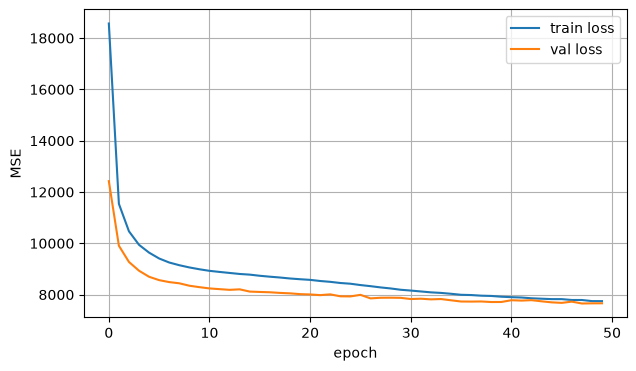

In [15]:
plt.figure(figsize=(7,4))
plt.plot(hist['loss'], label='train loss')
plt.plot(hist['val_loss'], label='val loss')
plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend(); plt.grid(); plt.show()

## 8. Evaluación en test

En regresión se suele reportar **R²** (qué proporción de la varianza explica el modelo; 1 = perfecto) y **RMSE** (error en las unidades originales, Wh).

In [16]:
model.eval()
with torch.no_grad():
    y_pred = model(torch.from_numpy(X_test).float().to(device)).squeeze(1).cpu().numpy()

r2 = r2_score(y_test, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
print(f"R2   = {r2:.4f}")
print(f"RMSE = {rmse:.1f} Wh")

R2   = 0.2391
RMSE = 87.3 Wh


## Recapitulación (lo que tenés que poder responder/armar)

1. **¿Cuál es el target?** La columna `Appliances`: numérica y continua → **regresión**.
2. **Salida del modelo:** `D_out=1`, **sin** sigmoid ni softmax, porque es regresión.
3. **Función de pérdida:** **MSE**.
4. **¿Por qué normalizar?** Para que todas las features tengan escala parecida y el descenso por el gradiente no oscile.
5. **¿Por qué ReLU en las ocultas?** La composición de lineales es lineal (no serviría de nada el MLP).
6. **¿Overfitting?** Se ve cuando `val_loss` sube mientras `train_loss` baja. Soluciones: weight_decay, dropout, early stopping, más datos.
